In [34]:
import numpy as np
import pandas as pd
import pickle
import matplotlib.pyplot as plt
import scipy.io

In [32]:
trial_info = scipy.io.loadmat(r"C:\Users\Almog\Downloads\NPC1_14082025_1_trial_info.mat")
trial_times = trial_info['trial_info'][0][0][0]
trial_times_maze = trial_times[31:-31] - 2

maze_video_path = r"C:\Maze\Video Data\NPC1_2025_08_14_13_02_08_stitched_blacked.mp4"
#Extract image from video
import cv2
cap = cv2.VideoCapture(maze_video_path)
ret, frame = cap.read()
if ret:
    maze_image = frame
cap.release()

folder_path = rf"C:\Maze\Video Data\\"
file_name = "NPC1_2025_08_14_13_02_08_stitched_blackedDLC_Resnet101_Neuropixel_2Cams_GammaJul22shuffle4_snapshot_100_filtered"
bodyparts = ['ear_R', 'ear_L', 'midbody', 'tailbase', 'headstage']
# Read the h5 file, update the path to the raw h5 DLC outputs
h5_file = pd.read_hdf(folder_path + file_name + ".h5")
# Update to be the actual file name according to the first index column value of the h5 table
table_name = 'DLC_Resnet101_Neuropixel_2Cams_GammaJul22shuffle4_snapshot_100'

# Load the DataFrame from the HDF5 file
dlc_raw_h5 = h5_file[table_name]

# Extract the MultiIndex from the first two rows
multi_index = pd.MultiIndex.from_arrays([dlc_raw_h5.iloc[0], dlc_raw_h5.iloc[1]])

# Convert the data to numeric, errors='coerce' will turn non-numeric values into NaN
dlc_raw_h5 = dlc_raw_h5.apply(pd.to_numeric, errors='coerce')

new_index = pd.MultiIndex.from_tuples([
        ('weighted', 'x'),
        ('weighted', 'y'),
        ('weighted', 'likelihood')
    ])

new_index_df = pd.DataFrame(np.nan, index=range(len(dlc_raw_h5)), columns=new_index)


# Concatenate the original DataFrame with the new columns DataFrame
# dlc_raw_h5 = pd.concat([dlc_raw_h5, new_columns], axis=1)

dlc_raw_h5 = pd.concat([dlc_raw_h5, new_index_df], axis=1)
dlc_raw_h5

headstage                              ear_L                         \
                 x           y likelihood           x           y likelihood   
0       184.620743  393.839142   0.314839  170.812988  394.578796   0.232403   
1       565.655945  394.058563   0.319597  573.955994  394.748352   0.356750   
2       565.655945  394.149231   0.363938  574.107788  394.748352   0.382715   
3       565.655945  394.149231   0.364500  574.212891  394.646393   0.381669   
4       565.585510  394.314728   0.383539  574.226379  394.646393   0.400387   
...            ...         ...        ...         ...         ...        ...   
205113  920.325073  643.516663   0.719884  912.252930  658.272095   0.830193   
205114  920.325073  637.020691   0.801138  912.638367  650.762634   0.852363   
205115  921.349487  628.565735   0.770397  912.654480  644.376587   0.887263   
205116  921.349487  620.853638   0.803617  912.654480  634.799744   0.846309   
205117  920.256165  615.786377   0.702157  912.638367  628.697876   0.931550   

             ear_R                            midbody                         \
                 x           y likelihood           x           y likelihood   
0       171.774490  385.411896   0.374243  154.037262  384.716217   0.231249   
1       569.211792  385.448029   0.353859  586.089417  384.759186   0.151622   
2       569.211792  385.449982   0.383622  586.089417  384.840698   0.168177   
3       569.211792  385.449982   0.371420  586.089417  384.759186   0.165211   
4       569.211792  385.450958   0.375259  585.909241  384.759186   0.167901   
...            ...         ...        ...         ...         ...        ...   
205113  930.794922  659.075806   0.860223  924.302246  681.620911   0.883159   
205114  930.935730  652.220642   0.782698  922.999146  676.149292   0.962473   
205115  930.935730  645.722717   0.891468  922.658936  669.100037   0.884543   
205116  930.794922  636.037537   0.811664  922.338501  660.033081   0.967877   
205117  930.240173  632.550903   0.822218  922.242615  654.030579   0.889599   

          tailbase                        weighted                 
                 x           y likelihood        x   y likelihood  
0       251.394730  142.634338   0.247685      NaN NaN        NaN  
1       568.445007  392.507446   0.262844      NaN NaN        NaN  
2       568.445007  392.507446   0.272712      NaN NaN        NaN  
3       574.612061  472.025696   0.257550      NaN NaN        NaN  
4       574.576965  472.025696   0.260254      NaN NaN        NaN  
...            ...         ...        ...      ...  ..        ...  
205113  934.587463  706.189880   0.837072      NaN NaN        NaN  
205114  928.962402  702.176575   0.758024      NaN NaN        NaN  
205115  927.102539  695.640015   0.805357      NaN NaN        NaN  
205116  926.310486  687.683167   0.833578      NaN NaN        NaN  
205117  925.012817  680.774963   0.735154      NaN NaN        NaN  

[205118 rows x 18 columns]

## Likelihood stats, valid-range detection, and speed-based jump detection
This section builds:
- Per-bodypart likelihood statistics within a consistent (in-maze) range
- Utilities to compute per-frame speeds for any bodypart (with configurable window)
- Trial-wise plotting over the maze image, highlighting speed outliers ("jumps")


In [63]:
# Run-time configuration (you can edit these values and re-run)
DLC_FPS = 40                 # frames per second for this dataset
N_TRIALS = 6                 # how many trials to plot (set None for all)
SAVE_DIR = None              # e.g., r"C:\\Maze\\Plots"; set to None to skip saving
HEAD_BP = 'headstage'        # bodypart to focus on in plots
TRIAL_TIMES_MODE = 'durations'  # 'durations' (seconds per trial) | 'seconds' (start/end) | 'frames'
MIN_TRIAL_LEN_S = 1.0        # minimum trial length (seconds) to plot
FIXED_TRIAL_LEN_S = 15.0     # fallback length if segments are not provided explicitly

# Single window size used both for speed displacement and rolling percentile threshold
WIN = 20  # frames

# Adaptive jump detection parameters (rolling percentile)
PCTL = 0.99                 # mark as jump if speed > rolling PCTL within a centered window
THR_WIN_FRAMES = 4 * WIN + 1 # use same window size as speed

# Legacy (no longer used for detection when adaptive mode is active)
K_MAD = 6.0      # kept for backward compatibility; ignored by adaptive detector
ABS_FLOOR = 25.0 # kept for backward compatibility; ignored by adaptive detector


In [64]:
# Helpers: column access, likelihood stats, valid-range detection, and speeds
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from typing import Tuple, List

# Config (feel free to tweak)
LIKE_THR = 0.6           # frame considered reliable if likelihood >= LIKE_THR
MIN_GOOD_FRAMES = 90     # minimal consecutive reliable frames to mark start/end of consistent region (~3s at 40fps)
GOOD_FRAC = 0.6          # fraction of bodyparts that must be reliable in a frame
DEFAULT_FPS = globals().get('DLC_FPS', 40)


def _locate_col(df: pd.DataFrame, bp: str, coord: str):
    """Return a Series for given bodypart and coord ('x','y','likelihood').
    Works for DLC-style MultiIndex columns or flat names like 'headstage_x'."""
    coord = coord.lower()
    # MultiIndex (any depth)
    if isinstance(df.columns, pd.MultiIndex):
        # prefer columns where last level equals coord and any level equals bp
        candidates = [c for c in df.columns if (isinstance(c, tuple) and len(c) >= 2 and str(c[-1]).lower() == coord and any(str(x) == bp for x in c))]
        if not candidates:
            # fallback: bodypart match ignoring case/underscores
            bp_key = bp.replace('_','').lower()
            candidates = [c for c in df.columns if (isinstance(c, tuple) and len(c) >= 2 and str(c[-1]).lower() == coord and any(str(x).replace('_','').lower() == bp_key for x in c))]
        if candidates:
            return df[candidates[0]]
        # try ('bp', 'coord') exact pair if exists
        simple = (bp, coord)
        if simple in df.columns:
            return df[simple]
        # try ('weighted', coord) as a safe fallback
        w = ('weighted', coord)
        if w in df.columns:
            return df[w]
    # Flat columns
    flat_names = [f'{bp}_{coord}', f'{bp.lower()}_{coord}', f'{bp.replace("_","")}_{coord}']
    for name in flat_names:
        if name in df.columns:
            return df[name]
    # Last resort: search by suffix
    for c in map(str, df.columns):
        if c.lower().endswith(f'_{coord}') and bp.lower() in c.lower():
            return df[c]
    raise KeyError(f'Could not locate column for {bp} {coord}.')


def get_xy_like(df: pd.DataFrame, bp: str) -> Tuple[pd.Series, pd.Series, pd.Series]:
    x = _locate_col(df, bp, 'x')
    y = _locate_col(df, bp, 'y')
    # likelihood might be missing for some bodyparts; if so, make ones
    try:
        l = _locate_col(df, bp, 'likelihood')
    except KeyError:
        l = pd.Series(np.ones(len(df), dtype=float), index=df.index)
    return x.astype(float), y.astype(float), l.astype(float)


def detect_consistent_range(df: pd.DataFrame, bodyparts: List[str], like_thr=LIKE_THR, good_frac=GOOD_FRAC, min_run=MIN_GOOD_FRAMES) -> Tuple[int,int]:
    """Detect indices [start, end) for the consistent in-maze range by looking at
    how many bodyparts have likelihood >= like_thr. Requires at least good_frac of bodyparts
    to be reliable and to persist for min_run frames. Returns (start_idx, end_idx_exclusive)."""
    n = len(df)
    good_counts = np.zeros(n, dtype=int)
    for bp in bodyparts:
        try:
            _, _, l = get_xy_like(df, bp)
            good_counts += (l.values >= like_thr).astype(int)
        except Exception:
            # missing bodypart -> ignore
            pass
    needed = max(1, int(np.ceil(good_frac * max(1, len(bodyparts)))))
    good = good_counts >= needed
    # find first run of min_run Trues
    start = 0
    run = 0
    found_start = None
    for i, v in enumerate(good):
        if v:
            run += 1
            if run >= min_run:
                found_start = i - run + 1
                break
        else:
            run = 0
    if found_start is None:
        found_start = 0
    # find last run from the end
    run = 0
    found_end = None
    for i in range(n-1, -1, -1):
        if good[i]:
            run += 1
            if run >= min_run:
                found_end = i + 1
                break
        else:
            run = 0
    if found_end is None or found_end <= found_start:
        found_end = n
    return found_start, found_end


def speed_series(df: pd.DataFrame, bp: str, window: int = 1) -> pd.Series:
    """Compute speed (pixels/frame) for a bodypart.
    window = 1 uses frame-to-frame displacement; window>1 uses t vs t-window displacement / window.
    Returns a Series aligned to df index with NaN for the first 'window' frames."""
    x, y, _ = get_xy_like(df, bp)
    if window < 1:
        window = 1
    dx = x.diff(periods=window)
    dy = y.diff(periods=window)
    sp = np.hypot(dx, dy) / float(window)
    return sp


def like_stats(df: pd.DataFrame, bodyparts: List[str], valid_start: int, valid_end: int) -> pd.DataFrame:
    """Return a DataFrame of likelihood statistics per bodypart, computed only within [valid_start, valid_end)."""
    stats = []
    sl = slice(valid_start, valid_end)
    for bp in bodyparts:
        try:
            _, _, l = get_xy_like(df, bp)
            lv = l.iloc[sl].astype(float)
            stats.append({
                'bodypart': bp,
                'count': int(lv.notna().sum()),
                'mean': float(lv.mean()),
                'median': float(lv.median()),
                'p10': float(lv.quantile(0.10)),
                'p50': float(lv.quantile(0.50)),
                'p90': float(lv.quantile(0.90)),
                'p95': float(lv.quantile(0.95)),
                'above_thr_frac': float((lv >= LIKE_THR).mean()),
            })
        except Exception as e:
            stats.append({'bodypart': bp, 'error': str(e)})
    return pd.DataFrame(stats).set_index('bodypart')


def segments_from_times(trial_times, n_frames: int, fps: int = DEFAULT_FPS, valid_start: int = 0, valid_end: int | None = None) -> List[Tuple[int,int]]:
    """Convert trial times into frame segments [start,end) using TRIAL_TIMES_MODE.
    Modes:
      - 'durations': 1D array of trial lengths in seconds. Segments are cumulative from valid_start.
      - 'seconds':   (N,2) start/end in seconds OR 1D start times -> consecutive pairs (seconds).
      - 'frames':    like 'seconds' but values already in frames.
    valid_start/valid_end clip segments to the consistent region.
    """
    mode = str(globals().get('TRIAL_TIMES_MODE', 'durations')).lower()
    end_limit = int(valid_end) if valid_end is not None else int(n_frames)

    arr = np.asarray(trial_times)
    arr = np.squeeze(arr)

    if mode == 'durations':
        # array of durations (seconds)
        if arr.ndim == 2 and arr.shape[1] == 1:
            arr = arr.reshape(-1)
        durations_s = arr.astype(float)
        # guard negatives
        durations_s = np.where(np.isfinite(durations_s), np.maximum(durations_s, 0.0), 0.0)
        lengths = np.round(durations_s * fps).astype(int)
        segs: List[Tuple[int,int]] = []
        s = int(valid_start)
        for L in lengths:
            if L <= 0:
                continue
            e = s + int(L)
            if e > end_limit:
                e = end_limit
            if e > s:
                segs.append((s, e))
            s = e
            if s >= end_limit:
                break
        return segs

    # For 'seconds' and 'frames', accept (N,2) or 1D starts
    if arr.ndim == 1 or (arr.ndim == 2 and arr.shape[1] == 1):
        starts = arr.astype(float).reshape(-1)
        starts = np.unique(np.sort(starts))
        if len(starts) < 2:
            return []
        if mode == 'frames':
            segs_f = np.column_stack([starts[:-1], starts[1:]])
        else:  # seconds
            segs_f = np.column_stack([starts[:-1]*fps, starts[1:]*fps])
    else:
        # Try to coerce to (-1,2)
        if arr.ndim >= 2 and (arr.shape[-1] != 2):
            for ax in range(arr.ndim):
                if arr.shape[ax] == 2:
                    arr = np.moveaxis(arr, ax, -1)
                    break
        if arr.ndim == 1 and arr.size % 2 == 0:
            arr = arr.reshape(-1, 2)
        if arr.ndim >= 2 and arr.shape[-1] == 2:
            arr = arr.reshape(-1, 2)
        if arr.ndim != 2 or arr.shape[1] != 2:
            raise ValueError('trial_times must be shape (N,2).')
        if mode == 'frames':
            segs_f = np.asarray(arr, dtype=float)
        else:
            segs_f = np.asarray(arr, dtype=float) * fps

    segs = np.round(segs_f).astype(int)
    # clip to valid range
    segs[:,0] = np.clip(segs[:,0] + int(valid_start), int(valid_start), end_limit-1)
    segs[:,1] = np.clip(segs[:,1] + int(valid_start), int(valid_start)+1, end_limit)
    segs[:,1] = np.maximum(segs[:,1], segs[:,0]+1)
    return [(int(s), int(e)) for s,e in segs]


# --- Adaptive percentile-based jump detection ---
def _rolling_percentile(arr: np.ndarray, window: int, p: float = 0.90) -> np.ndarray:
    """Centered rolling percentile (returns same-length array). NaNs propagated if insufficient data."""
    s = pd.Series(arr)
    w = max(3, int(window))
    thr = s.rolling(window=w, center=True, min_periods=max(3, w//2)).quantile(p)
    return thr.values


def speed_outliers_adaptive_pctl(x: np.ndarray, y: np.ndarray, speed_win: int = 20, thr_win: int | None = None, pctl: float = 0.90):
    """Compute speed (px/frame) using displacement over speed_win frames (t vs t-speed_win)/speed_win.
    Mark frames as jumps where speed > centered rolling pctl (default 90th percentile) over thr_win frames.
    Returns (speed, mask, thr_series, med, p90)."""
    if speed_win < 1:
        speed_win = 1
    dx = x - np.roll(x, speed_win)
    dy = y - np.roll(y, speed_win)
    sp = np.hypot(dx, dy) / float(speed_win)
    sp[:speed_win] = np.nan
    if thr_win is None:
        thr_win = speed_win * 3 + 1
    thr_series = _rolling_percentile(sp, window=thr_win, p=pctl)
    mask = (sp > thr_series) & np.isfinite(sp) & np.isfinite(thr_series)
    med = float(np.nanmedian(sp))
    p90 = float(np.nanpercentile(sp, 90)) if np.isfinite(sp).any() else float('nan')
    return sp, mask, thr_series, med, p90


In [21]:
# Compute valid range and likelihood statistics
# Detect the consistent in-maze segment once and compute per-bodypart stats
try:
    n_frames = len(dlc_raw_h5)
except NameError:
    raise RuntimeError("dlc_raw_h5 is not defined. Run the preparation cell first.")

# if bodyparts not defined, attempt to infer
if 'bodyparts' not in globals() or not isinstance(bodyparts, (list, tuple)):
    # guess from columns
    inferred = set()
    if isinstance(dlc_raw_h5.columns, pd.MultiIndex):
        for c in dlc_raw_h5.columns:
            if isinstance(c, tuple) and len(c) >= 2 and str(c[-1]).lower() in ('x','y','likelihood'):
                inferred.add(str(c[-2]))
    else:
        for c in map(str, dlc_raw_h5.columns):
            if c.lower().endswith('_x'):
                inferred.add(c[:-2])
    bodyparts = sorted(inferred)
    print('Inferred bodyparts:', bodyparts)

valid_start, valid_end = detect_consistent_range(dlc_raw_h5, bodyparts)
print(f"Consistent range: frames [{valid_start}, {valid_end}) of {n_frames} (length {valid_end-valid_start}).")

like_df = like_stats(dlc_raw_h5, bodyparts, valid_start, valid_end)
like_df_display = like_df.sort_values('median', ascending=False)
like_df_display

Consistent range: frames [204, 204915) of 205118 (length 204711).


,count,mean,median,p10,p50,p90,p95,above_thr_frac
bodypart,,,,,,,,
midbody,204711,0.891818,0.904036,0.810988,0.904036,0.995982,1.000000,0.977822
headstage,204711,0.878396,0.897327,0.760303,0.897327,0.991227,1.000000,0.976621
ear_L,204711,0.871785,0.892707,0.743424,0.892707,0.985220,1.000000,0.969288
ear_R,204711,0.846892,0.875783,0.705864,0.875783,0.961986,0.976418,0.957164
tailbase,204711,0.784012,0.810253,0.577411,0.810253,0.959307,1.000000,0.885150


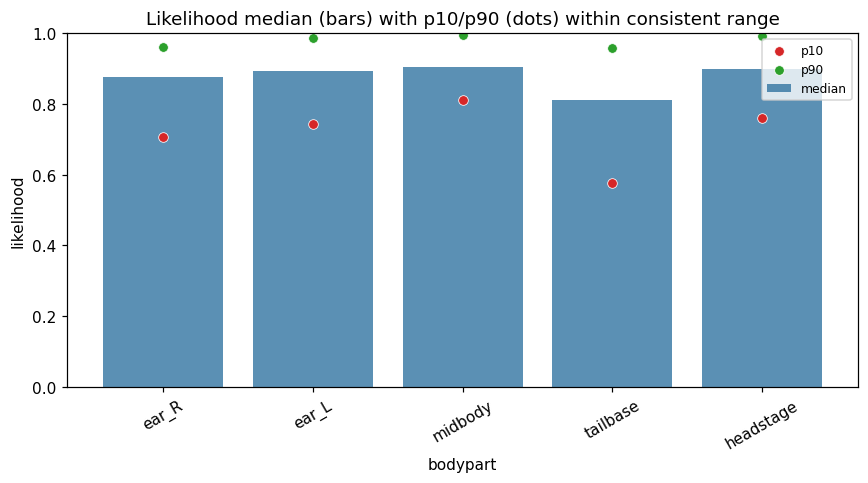

In [22]:
# Plot a quick overview of likelihood distributions for sanity
import seaborn as sns
plt.figure(figsize=(8,4.5), dpi=110)
sns.barplot(x=like_df.index, y=like_df['median'], color='#1f77b4', alpha=0.8, label='median')
sns.scatterplot(x=like_df.index, y=like_df['p10'], color='#d62728', s=40, label='p10')
sns.scatterplot(x=like_df.index, y=like_df['p90'], color='#2ca02c', s=40, label='p90')
plt.ylim(0,1.0)
plt.ylabel('likelihood')
plt.title('Likelihood median (bars) with p10/p90 (dots) within consistent range')
plt.xticks(rotation=30)
plt.legend(loc='best', fontsize=8)
plt.tight_layout(); plt.show()

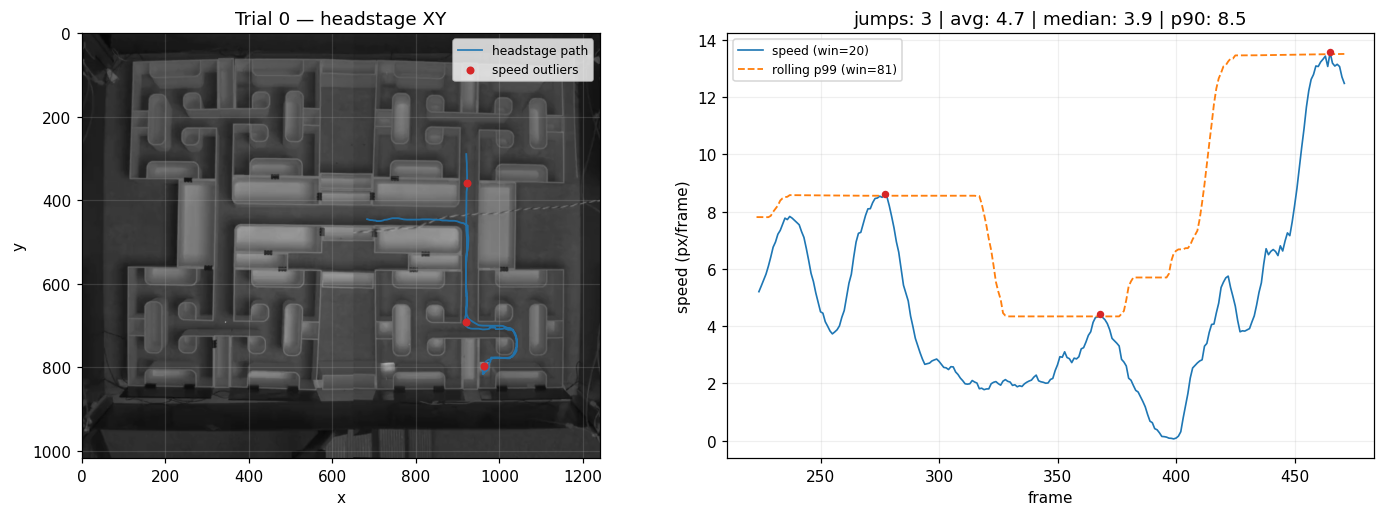

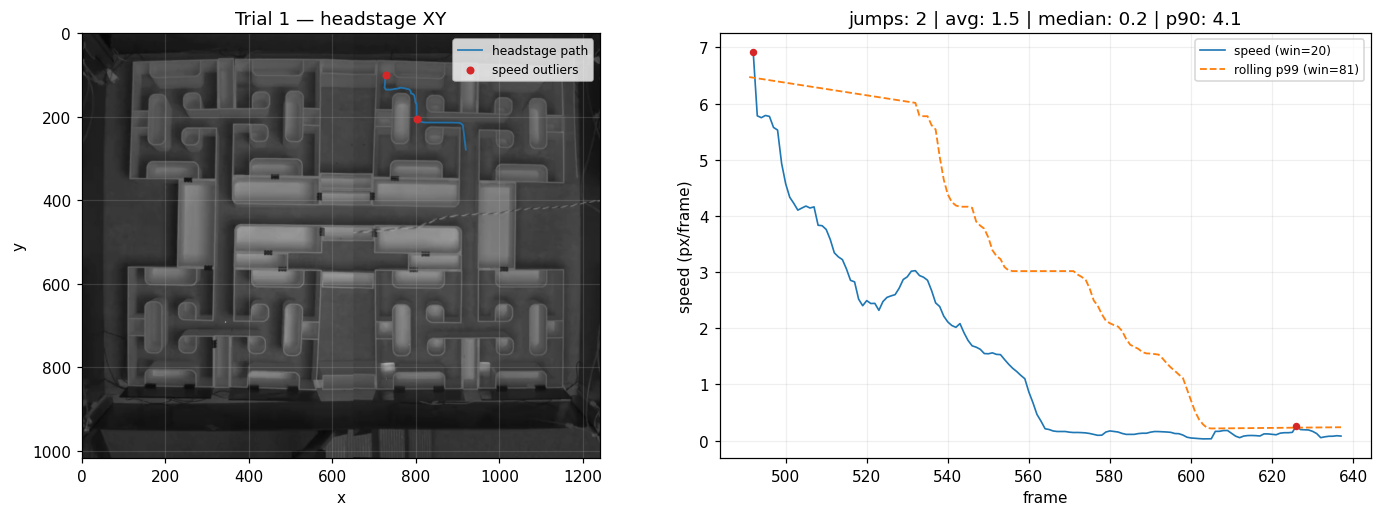

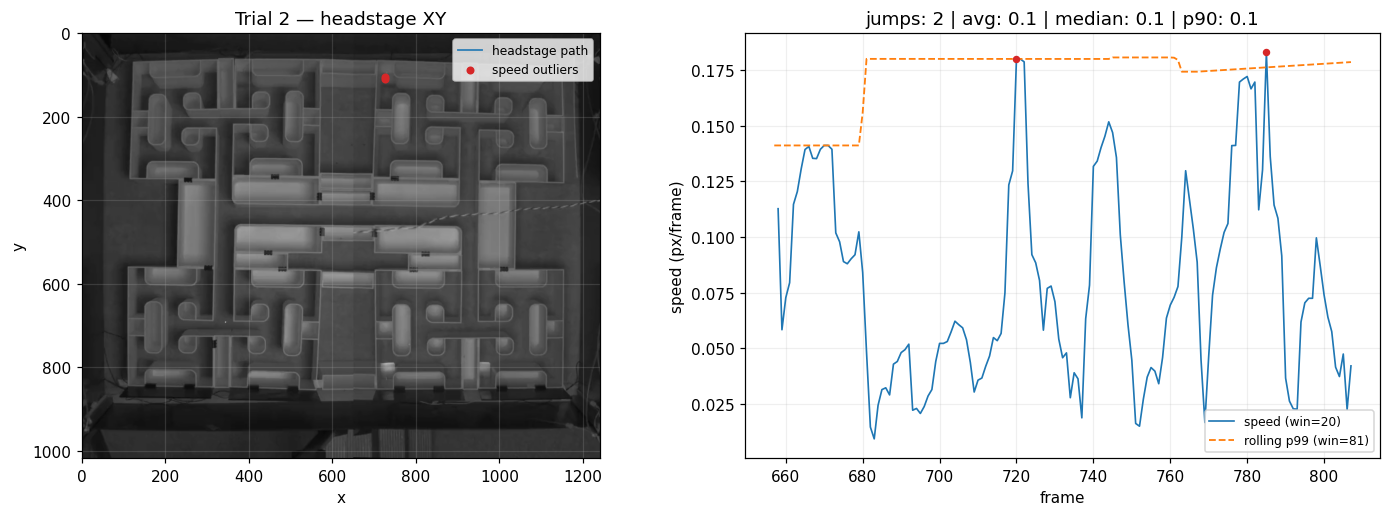

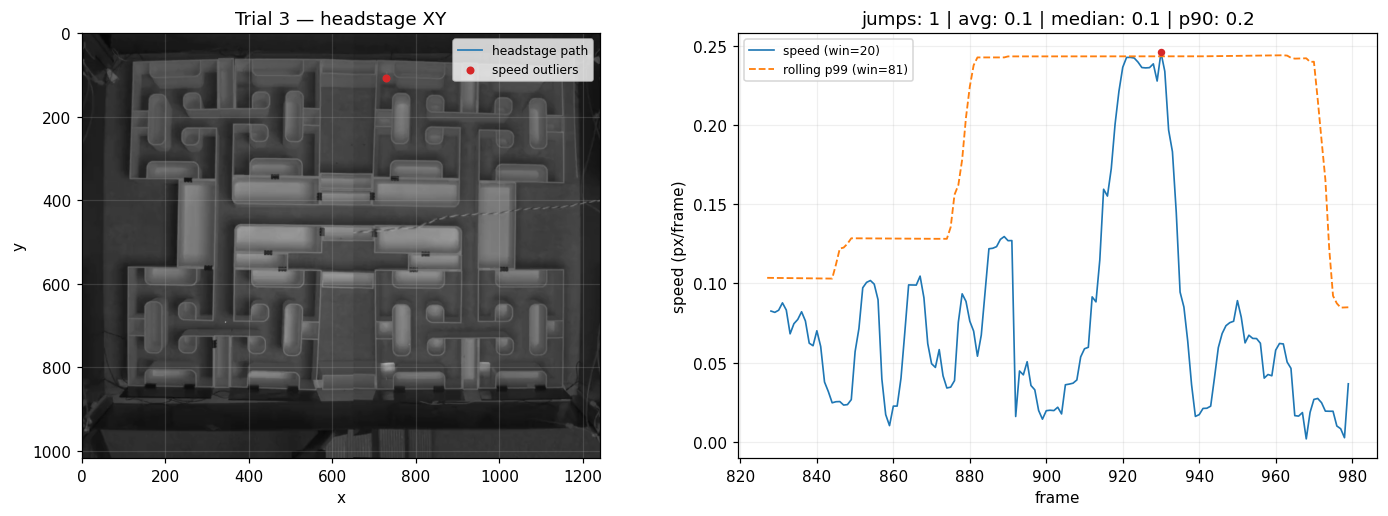

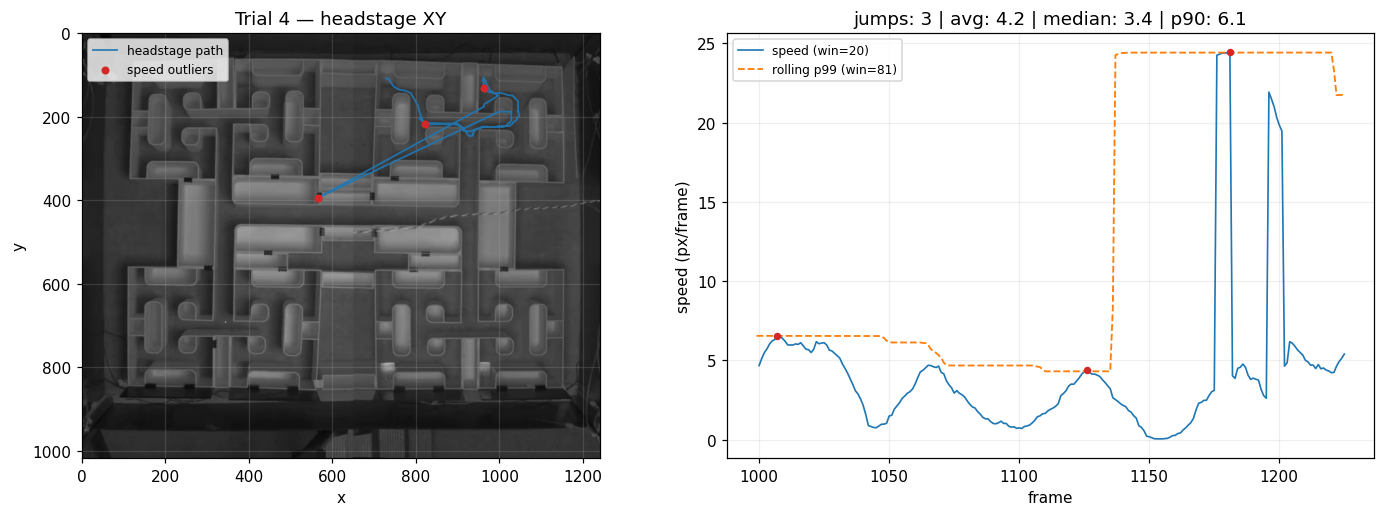

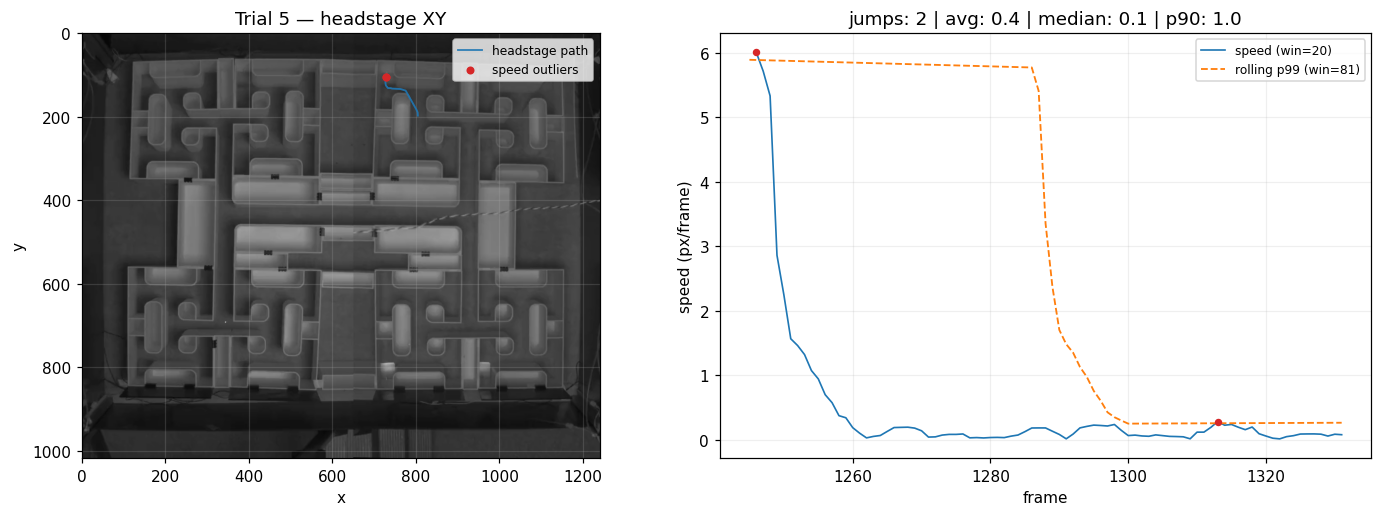

Plotted first 6 trials (set N_TRIALS to change).


,trial,frame_start,frame_end,n_frames,n_jumps,avg_speed,median_speed,p90_speed,thr
0,0,204,472,268,3,4.690135,3.872025,8.482429,8.555180
1,1,472,638,166,2,1.472037,0.237333,4.120749,3.016712
2,2,638,808,170,2,0.078937,0.071645,0.141048,0.179994
3,3,808,980,172,1,0.076661,0.062031,0.182069,0.242678
4,4,980,1226,246,3,4.190570,3.398057,6.093002,6.546316
5,5,1226,1332,106,2,0.448138,0.100864,1.011163,3.356546


In [65]:
# Trial-wise plotting for headstage: overlay on maze image and mark speed-based outliers
PLOT_MAX_TRIALS = globals().get('N_TRIALS', 6)
HEAD_BP = globals().get('HEAD_BP', 'headstage')
SAVE_DIR = globals().get('SAVE_DIR', None)

# detection params for jumps (adaptive percentile)
WIN = int(globals().get('WIN', 20))                     # frames for speed displacement
PCTL = float(globals().get('PCTL', 0.95))               # rolling percentile level
THR_WIN_FRAMES = int(globals().get('THR_WIN_FRAMES', 3*WIN + 1))  # centered window for threshold
MIN_TRIAL_LEN_S = float(globals().get('MIN_TRIAL_LEN_S', 3.0))    # minimum trial length to plot (seconds)
FIXED_TRIAL_LEN_S = float(globals().get('FIXED_TRIAL_LEN_S', 15.0))  # fallback fixed length when segments too short

# resolve headstage columns (fallback to first bodypart if missing)
try:
    hs_x, hs_y, hs_l = get_xy_like(dlc_raw_h5, HEAD_BP)
except Exception:
    if len(bodyparts) == 0:
        raise RuntimeError('No bodyparts available to plot.')
    print(f"'{HEAD_BP}' not found; using '{bodyparts[0]}' instead.")
    HEAD_BP = bodyparts[0]
    hs_x, hs_y, hs_l = get_xy_like(dlc_raw_h5, HEAD_BP)

# restrict to consistent range for speed computation
x_all = hs_x.values.astype(float)
y_all = hs_y.values.astype(float)
mask_valid = np.zeros(len(dlc_raw_h5), dtype=bool)
mask_valid[valid_start:valid_end] = True

# prepare trial segments
if 'trial_times_maze' not in globals():
    if 'trial_times' in globals():
        print('trial_times_maze not found; using trial_times as fallback.')
        trial_times_maze = np.asarray(trial_times)
    else:
        raise RuntimeError("trial_times_maze is not defined. Load it in the preparation cell.")

# Optional time offset in seconds to apply before converting to frames (set TRIAL_TIME_OFFSET_S globally)
TRIAL_TIME_OFFSET_S = float(globals().get('TRIAL_TIME_OFFSET_S', 0.0))
if TRIAL_TIME_OFFSET_S != 0.0:
    try:
        tt = np.asarray(trial_times_maze, dtype=float)
        tt = tt + TRIAL_TIME_OFFSET_S
        trial_times_maze = tt
    except Exception:
        pass

segs = segments_from_times(trial_times_maze, len(dlc_raw_h5), fps=DEFAULT_FPS)

# If all segments end up too short after clipping to valid range, fallback to fixed windows from starts
min_frames = max(int(round(MIN_TRIAL_LEN_S * DEFAULT_FPS)), WIN + 1)
eligible = []
for (s, e) in segs:
    s2 = max(s, valid_start); e2 = min(e, valid_end)
    if e2 - s2 >= min_frames:
        eligible.append((s2, e2))

if len(eligible) == 0:
    # derive starts (seconds) and build fixed windows
    starts = np.squeeze(np.asarray(trial_times_maze)).astype(float).reshape(-1)
    starts = np.unique(np.sort(starts))
    s_frames = np.round(starts * DEFAULT_FPS).astype(int)
    for sf in s_frames:
        s2 = max(int(sf), int(valid_start))
        e2 = min(int(sf + FIXED_TRIAL_LEN_S * DEFAULT_FPS), int(valid_end))
        if e2 - s2 >= min_frames:
            eligible.append((s2, e2))
    if len(eligible) == 0:
        print('No eligible trials to plot even after fixed-window fallback. Consider lowering MIN_TRIAL_LEN_S or check trial_times_maze.')
        eligible = []

# try to get maze image
maze_img = globals().get('maze_image', None)

# ensure save dir exists if provided
if isinstance(SAVE_DIR, str) and len(SAVE_DIR) > 0:
    import os
    os.makedirs(SAVE_DIR, exist_ok=True)

trial_rows = []
n_plots = 0
for idx, (s2, e2) in enumerate(eligible):
    if isinstance(PLOT_MAX_TRIALS, int) and PLOT_MAX_TRIALS > 0 and n_plots >= PLOT_MAX_TRIALS:
        print(f"Plotted first {PLOT_MAX_TRIALS} trials (set N_TRIALS to change).")
        break

    xi = x_all[s2:e2]
    yi = y_all[s2:e2]

    # Adaptive percentile-based detection
    sp, out_mask, thr_series, med, p90 = speed_outliers_adaptive_pctl(
        xi, yi, speed_win=WIN, thr_win=THR_WIN_FRAMES, pctl=PCTL
    )
    avg_speed = float(np.nanmean(sp))
    med_speed = float(np.nanmedian(sp))
    p90_speed = float(np.nanpercentile(sp, 90))
    n_out = int(np.nansum(out_mask))
    thr_summary = float(np.nanmedian(thr_series))

    fig, axes = plt.subplots(1, 2, figsize=(13.2, 4.8), dpi=110)

    # Overlay on maze
    ax = axes[0]
    if maze_img is not None:
        ax.imshow(maze_img, origin='upper')
        h, w = maze_img.shape[:2]
        ax.set_xlim(0, w); ax.set_ylim(h, 0)  # image coords
    ax.plot(xi, yi, color='#1f77b4', lw=1.2, alpha=0.9, label=f'{HEAD_BP} path')
    if np.any(out_mask):
        ax.scatter(xi[out_mask], yi[out_mask], c='#d62728', s=18, label='speed outliers', zorder=3)
    ax.set_title(f'Trial {idx} — {HEAD_BP} XY')
    ax.set_xlabel('x'); ax.set_ylabel('y'); ax.legend(fontsize=8); ax.grid(alpha=0.2)
    ax.set_aspect('equal', adjustable='box')

    # Speed trace with rolling threshold
    ax2 = axes[1]
    tt = np.arange(s2, e2)
    ax2.plot(tt, sp, color='#1f77b4', lw=1.1, label=f'speed (win={WIN})')
    ax2.plot(tt, thr_series, color='#ff7f0e', ls='--', lw=1.2, label=f'rolling p{int(PCTL*100)} (win={THR_WIN_FRAMES})')
    if np.any(out_mask):
        ax2.scatter(tt[out_mask], sp[out_mask], c='#d62728', s=15, zorder=3)
    ax2.set_title(f"jumps: {n_out} | avg: {avg_speed:.1f} | median: {med_speed:.1f} | p90: {p90_speed:.1f}")
    ax2.set_xlabel('frame'); ax2.set_ylabel('speed (px/frame)')
    ax2.legend(fontsize=8); ax2.grid(alpha=0.2)

    plt.tight_layout()

    # Optional save
    if isinstance(SAVE_DIR, str) and len(SAVE_DIR) > 0:
        import os
        fname = f"trial_{idx:03d}_frames_{s2}_{e2}_j{n_out}.png"
        plt.savefig(os.path.join(SAVE_DIR, fname), dpi=150)

    plt.show()
    n_plots += 1

    trial_rows.append({
        'trial': idx,
        'frame_start': s2,
        'frame_end': e2,
        'n_frames': e2 - s2,
        'n_jumps': n_out,
        'avg_speed': avg_speed,
        'median_speed': med_speed,
        'p90_speed': p90_speed,
        'thr': thr_summary,
    })

# Summarize trial-level statistics and optionally save
import pandas as pd
trial_stats = pd.DataFrame(trial_rows)
if len(trial_stats):
    display(trial_stats)
    if isinstance(SAVE_DIR, str) and len(SAVE_DIR) > 0:
        import os
        trial_csv = os.path.join(SAVE_DIR, 'trial_speed_stats.csv')
        trial_stats.to_csv(trial_csv, index=False)
        print('Saved trial stats to:', trial_csv)
else:
    print('No eligible trials to plot (check trial_times_maze and consistent range, or lower MIN_TRIAL_LEN_S / increase FIXED_TRIAL_LEN_S).')


In [24]:
# Inspect trial_times variables for shape debugging
import numpy as np
vars_to_check = []
if 'trial_times_maze' in globals():
    vars_to_check.append(('trial_times_maze', np.asarray(trial_times_maze)))
if 'trial_times' in globals():
    vars_to_check.append(('trial_times', np.asarray(trial_times)))
for name, arr in vars_to_check:
    print(name, 'type=', type(arr), 'shape=', arr.shape, 'ndim=', arr.ndim)
    if arr.size <= 20:
        print('values:', arr)
    else:
        print('first rows:', np.asarray(arr).reshape(-1, arr.shape[-1])[:3] if arr.ndim>1 else arr[:10])

trial_times_maze type= <class 'numpy.ndarray'> shape= (935, 1) ndim= 2
first rows: [[11.8051    ]
 [ 4.14196667]
 [ 4.2557    ]]
trial_times type= <class 'numpy.ndarray'> shape= (997, 1) ndim= 2
first rows: [[62.0504    ]
 [62.05036667]
 [62.0503    ]]
